# GSI Annotation Statistics — `fixed_batches_20_GSI_all_entities`

Reads the digit-prefixed JSON files (e.g. `0001_Abatus_cordatus_abj.json`) from every species folder across all 20 batches.

**What is counted:** whether the `fixed_text` field contains at least one `[GSI = ...` annotation.

**Statistics:**
- How many species **have** a GSI annotation
- How many species **do not** have a GSI annotation
- Breakdown per batch

In [1]:
import json
import re
from pathlib import Path
import pandas as pd

base_dir = Path("../fixed_batches_20_GSI_all_entities")

GSI_PATTERN = re.compile(r"\[GSI\s*=")

records = []

for batch_dir in sorted(base_dir.iterdir()):
    if not batch_dir.is_dir() or not batch_dir.name.startswith("batch_"):
        continue
    for species_dir in sorted(batch_dir.iterdir()):
        if not species_dir.is_dir():
            continue
        for f in species_dir.iterdir():
            # digit-prefixed, no _audit in name
            if not (f.name[0].isdigit() and "audit" not in f.name and f.suffix == ".json"):
                continue
            data = json.loads(f.read_text())
            text = data.get("fixed_text", "")
            has_gsi = bool(GSI_PATTERN.search(text))
            n_gsi = len(GSI_PATTERN.findall(text))
            records.append({
                "batch":   batch_dir.name,
                "species": data.get("specie", species_dir.name),
                "file":    f.name,
                "has_gsi": has_gsi,
                "n_gsi_annotations": n_gsi,
            })

df = pd.DataFrame(records)
print(f"Total species files loaded: {len(df)}")
df.head()

Total species files loaded: 7281


,batch,species,file,has_gsi,n_gsi_annotations
0,batch_01,Abatus_cordatus,0001_Abatus_cordatus_abj.json,True,2
1,batch_01,Abbottina_rivularis,0002_Abbottina_rivularis_abj.json,False,0
2,batch_01,Ablennes_hians,0003_Ablennes_hians_abj.json,False,0
3,batch_01,Abra_segmentum,0004_Abra_segmentum_abj.json,False,0
4,batch_01,Abralia_multihamata,0005_Abralia_multihamata_abj.json,True,2


## 1 — Overall: species with vs without GSI annotation

Total species files      : 7281
With    GSI annotation   : 522  (7.2%)
Without GSI annotation   : 6759  (92.8%)


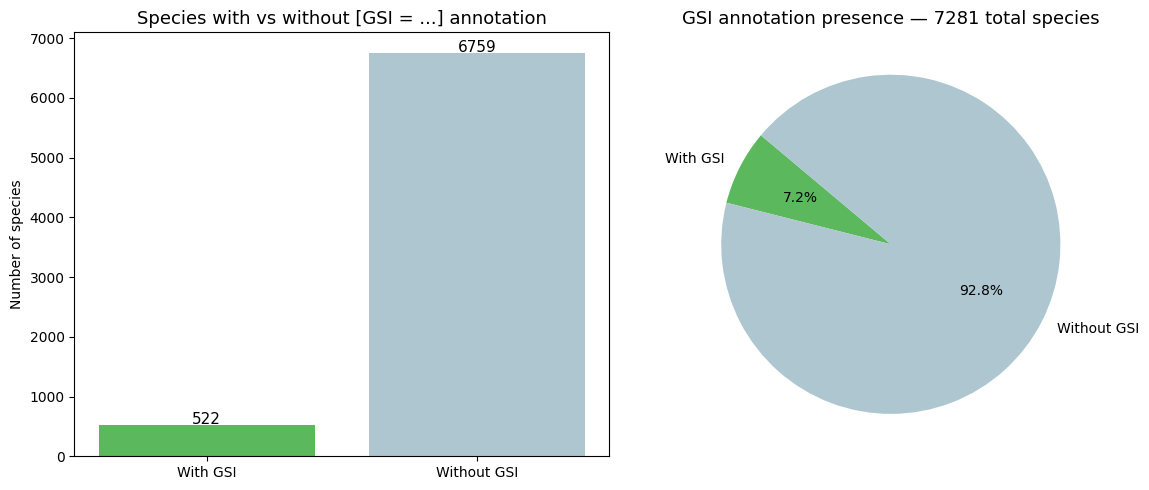

In [2]:
import matplotlib.pyplot as plt

with_gsi    = df["has_gsi"].sum()
without_gsi = (~df["has_gsi"]).sum()
total       = len(df)

print(f"Total species files      : {total}")
print(f"With    GSI annotation   : {with_gsi}  ({with_gsi/total*100:.1f}%)")
print(f"Without GSI annotation   : {without_gsi}  ({without_gsi/total*100:.1f}%)")

labels = ["With GSI", "Without GSI"]
values = [with_gsi, without_gsi]
bar_colors = ["#5cb85c", "#aec6cf"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(labels, values, color=bar_colors)
axes[0].set_title("Species with vs without [GSI = ...] annotation", fontsize=13)
axes[0].set_ylabel("Number of species")
for i, v in enumerate(values):
    axes[0].text(i, v + 15, str(v), ha="center", fontsize=11)

axes[1].pie(values, labels=labels, autopct="%1.1f%%", colors=bar_colors, startangle=140)
axes[1].set_title(f"GSI annotation presence — {total} total species", fontsize=13)

plt.tight_layout()
plt.show()

## 2 — Per-batch breakdown: with vs without GSI annotation

          with_gsi  without_gsi  total
Batch                                 
batch_01        26          344    370
batch_02        25          345    370
batch_03        22          348    370
batch_04        50          320    370
batch_05        22          348    370
batch_06        33          337    370
batch_07        25          345    370
batch_08        20          350    370
batch_09        25          345    370
batch_10        35          335    370
batch_11        32          338    370
batch_12        22          348    370
batch_13        16          354    370
batch_14        30          340    370
batch_15        30          340    370
batch_16        15          355    370
batch_17        35          335    370
batch_18        25          345    370
batch_19        27          343    370
batch_20         7          244    251


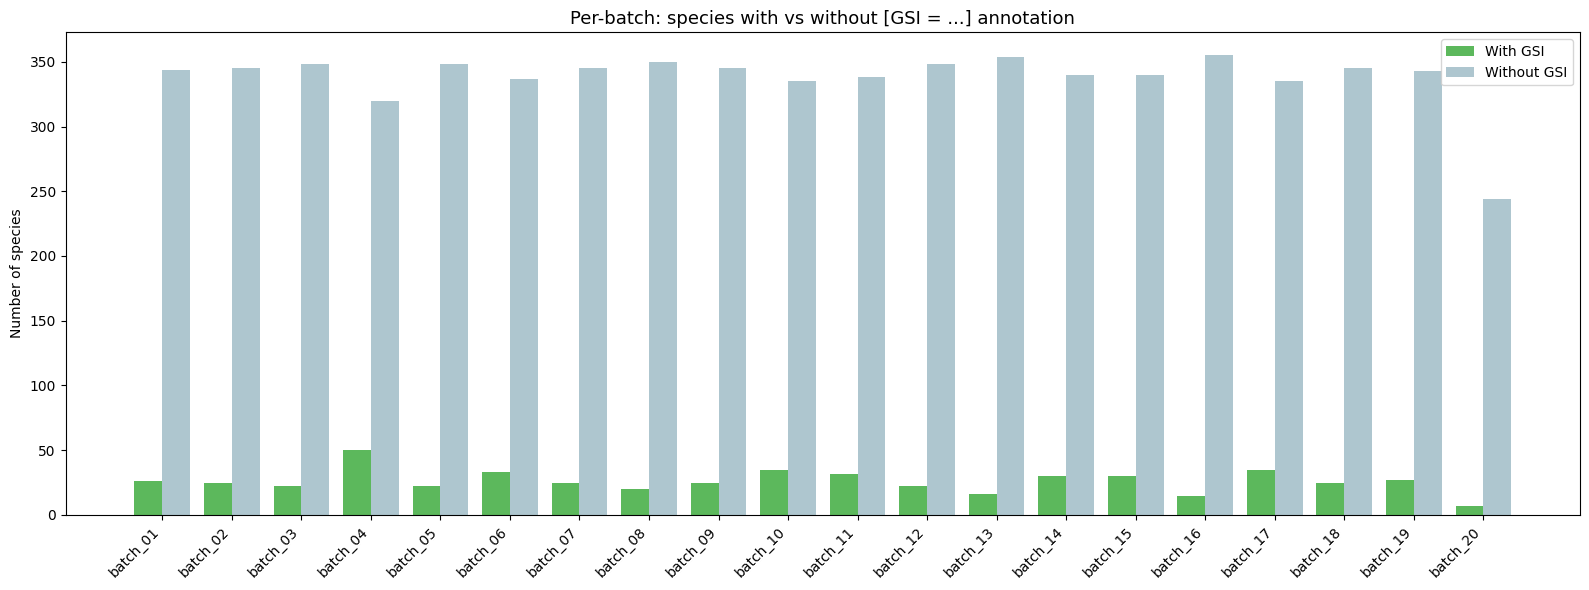

In [3]:
batch_stats = (
    df.groupby("batch")["has_gsi"]
    .agg(with_gsi="sum", total="count")
    .assign(without_gsi=lambda x: x["total"] - x["with_gsi"])
)
batch_stats.index.name = "Batch"
print(batch_stats[["with_gsi", "without_gsi", "total"]].to_string())

x = range(len(batch_stats))
width = 0.4

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar([xi - width/2 for xi in x], batch_stats["with_gsi"],    width, label="With GSI",    color="#5cb85c")
ax.bar([xi + width/2 for xi in x], batch_stats["without_gsi"], width, label="Without GSI", color="#aec6cf")
ax.set_title("Per-batch: species with vs without [GSI = ...] annotation", fontsize=13)
ax.set_ylabel("Number of species")
ax.set_xticks(list(x))
ax.set_xticklabels(batch_stats.index, rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

---

## `fixed_batches_20_GSI` — GSI annotation statistics in `*_gsi_audit.json` files

Reads digit-prefixed files ending with `_gsi_audit.json` (e.g. `0001_Abatus_cordatus_abj_gsi_audit.json`).  
Checks the `corrected_text_final` field for `[GSI = ...` annotations.

In [5]:
base_dir_gsi = Path("../fixed_batches_20_GSI")

records_gsi = []

for batch_dir in sorted(base_dir_gsi.iterdir()):
    if not batch_dir.is_dir() or not batch_dir.name.startswith("batch_"):
        continue
    for species_dir in sorted(batch_dir.iterdir()):
        if not species_dir.is_dir():
            continue
        for f in species_dir.iterdir():
            if not (f.name[0].isdigit() and f.name.endswith("_gsi_audit.json")):
                continue
            data = json.loads(f.read_text())
            text = data.get("corrected_text_final", "")
            has_gsi = bool(GSI_PATTERN.search(text))
            n_gsi = len(GSI_PATTERN.findall(text))
            records_gsi.append({
                "batch":             batch_dir.name,
                "species":           data.get("specie", species_dir.name),
                "file":              f.name,
                "has_gsi":           has_gsi,
                "n_gsi_annotations": n_gsi,
            })

df_gsi = pd.DataFrame(records_gsi)
print(f"Total _gsi_audit files loaded: {len(df_gsi)}")
df_gsi.head()

Total _gsi_audit files loaded: 7281


,batch,species,file,has_gsi,n_gsi_annotations
0,batch_01,Abatus_cordatus,0001_Abatus_cordatus_abj_gsi_audit.json,True,2
1,batch_01,Abbottina_rivularis,0002_Abbottina_rivularis_abj_gsi_audit.json,False,0
2,batch_01,Ablennes_hians,0003_Ablennes_hians_abj_gsi_audit.json,False,0
3,batch_01,Abra_segmentum,0004_Abra_segmentum_abj_gsi_audit.json,False,0
4,batch_01,Abralia_multihamata,0005_Abralia_multihamata_abj_gsi_audit.json,True,2


Total _gsi_audit files   : 7281
With    GSI annotation   : 530  (7.3%)
Without GSI annotation   : 6751  (92.7%)


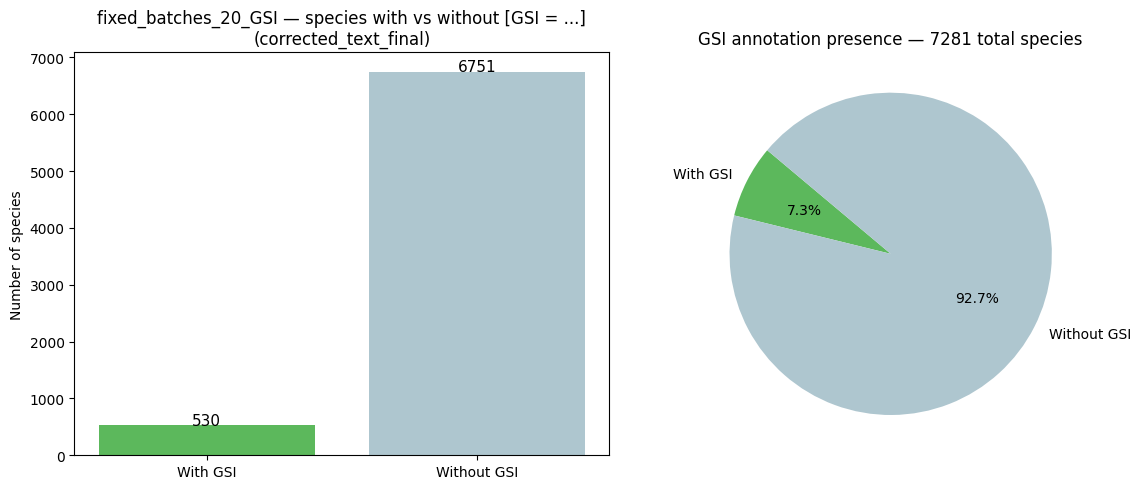

          with_gsi  without_gsi  total
Batch                                 
batch_01        26          344    370
batch_02        27          343    370
batch_03        22          348    370
batch_04        50          320    370
batch_05        22          348    370
batch_06        33          337    370
batch_07        26          344    370
batch_08        21          349    370
batch_09        25          345    370
batch_10        35          335    370
batch_11        32          338    370
batch_12        22          348    370
batch_13        16          354    370
batch_14        30          340    370
batch_15        30          340    370
batch_16        17          353    370
batch_17        35          335    370
batch_18        26          344    370
batch_19        28          342    370
batch_20         7          244    251


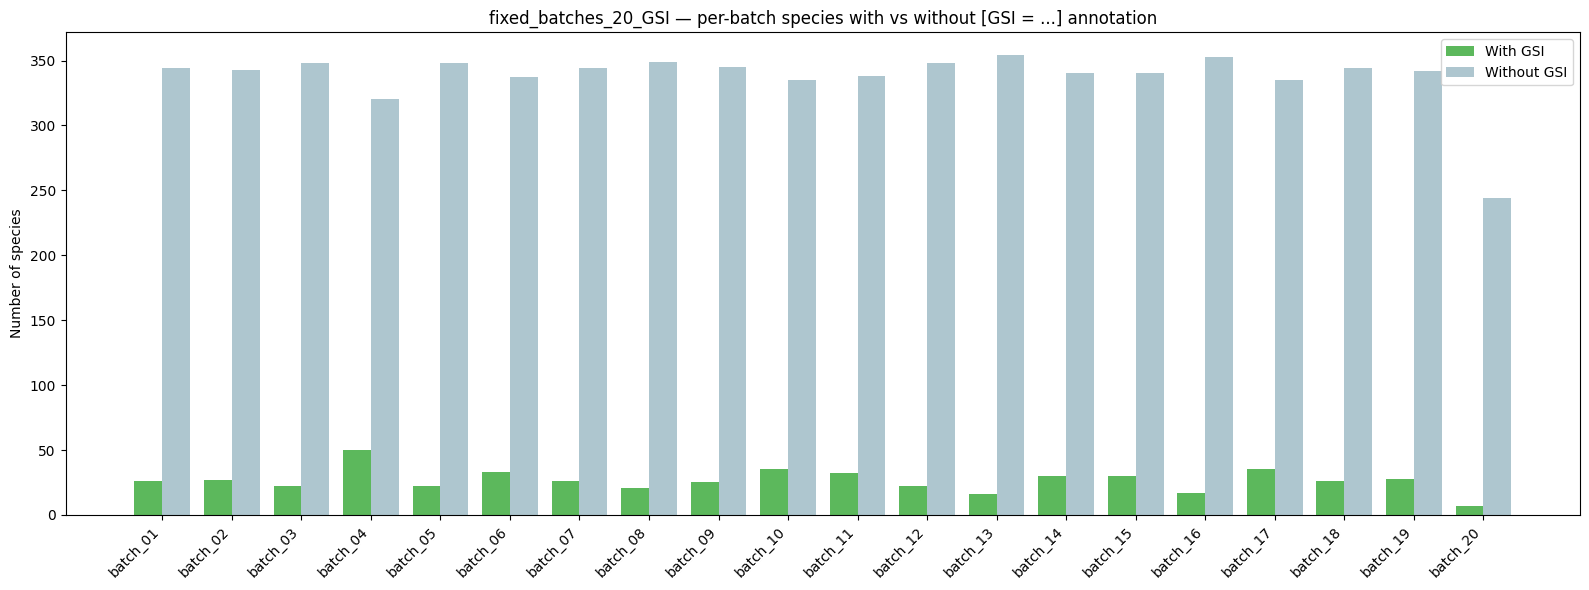

In [6]:
with_gsi_g    = df_gsi["has_gsi"].sum()
without_gsi_g = (~df_gsi["has_gsi"]).sum()
total_g       = len(df_gsi)

print(f"Total _gsi_audit files   : {total_g}")
print(f"With    GSI annotation   : {with_gsi_g}  ({with_gsi_g/total_g*100:.1f}%)")
print(f"Without GSI annotation   : {without_gsi_g}  ({without_gsi_g/total_g*100:.1f}%)")

labels_g = ["With GSI", "Without GSI"]
values_g  = [with_gsi_g, without_gsi_g]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(labels_g, values_g, color=bar_colors)
axes[0].set_title("fixed_batches_20_GSI — species with vs without [GSI = ...]\n(corrected_text_final)", fontsize=12)
axes[0].set_ylabel("Number of species")
for i, v in enumerate(values_g):
    axes[0].text(i, v + 10, str(v), ha="center", fontsize=11)

axes[1].pie(values_g, labels=labels_g, autopct="%1.1f%%", colors=bar_colors, startangle=140)
axes[1].set_title(f"GSI annotation presence — {total_g} total species", fontsize=12)

plt.tight_layout()
plt.show()

# Per-batch breakdown
batch_stats_gsi = (
    df_gsi.groupby("batch")["has_gsi"]
    .agg(with_gsi="sum", total="count")
    .assign(without_gsi=lambda x: x["total"] - x["with_gsi"])
)
batch_stats_gsi.index.name = "Batch"
print(batch_stats_gsi[["with_gsi", "without_gsi", "total"]].to_string())

x = range(len(batch_stats_gsi))
width = 0.4

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar([xi - width/2 for xi in x], batch_stats_gsi["with_gsi"],    width, label="With GSI",    color="#5cb85c")
ax.bar([xi + width/2 for xi in x], batch_stats_gsi["without_gsi"], width, label="Without GSI", color="#aec6cf")
ax.set_title("fixed_batches_20_GSI — per-batch species with vs without [GSI = ...] annotation", fontsize=12)
ax.set_ylabel("Number of species")
ax.set_xticks(list(x))
ax.set_xticklabels(batch_stats_gsi.index, rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()